##**CONTEXTO**

*Este dataset contiene información sobre las muertes viales registradas en la República Argentina entre 2017 y 2024, recopilada a través del Sistema de Alerta Temprana (SAT), perteneciente al Sistema Nacional de Información Criminal (SNIC). Los datos corresponden a microdatos e informes sobre personas fallecidas como consecuencia de hechos de tránsito, permitiendo analizar la distribución y evolución de las muertes viales en el país.*

##**OBJETIVO PRINCIPAL DEL PROYECTO**
Desarrollar un modelo predictivo de regresión (utilizando algoritmos de aprendizaje automático como Random Forest Regressor, Regresión Lineal y Regresión de Poisson) que permita estimar la cantidad de siniestros viales que involucran motocicletas en Argentina para el año 2024, a partir de condiciones espacio-temporales y viales observadas (franja horaria, tipo de lugar, temporada y provincia).

##**DONDE LO APLICARIAMOS**
Análisis de patrones de siniestralidad que puedan aportar información para orientar medidas preventivas.

## **PREGUNTA DEL NEGOCIO**

# ***¿Cuántos siniestros viales que involucren motos se pueden predecir para el año 2024, en Argentina, durante (franja horaria) en (estación del año/mes)?***

## **Variable objetivo (y):**

Cantidad de siniestros viales que involucran motocicletas (cantidad_siniestros_motos) — Variable cuantitativa discreta (conteo) obtenida mediante la agregación espacial y temporal de los hechos.

##**Variables predictoras (x):**
Franja horaria (franja_horaria) — Segmentada en Mañana, Tarde, Noche o Madrugada a partir de la hora del hecho.

Tipo de lugar (tipo_lugar) — Clasificado en Ruta, Autopista / Autovía, Avenida o Calle.

Temporada del año (temporada) — Derivada del mes del hecho (Verano, Otoño, Invierno o Primavera).

Ubicación geográfica (provincia_nombre) — Provincia donde se registra el siniestro.



Sección 1: Librerías, Configuración e Importación del Dataset

In [3]:
#Imports y configuración
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


print("pandas    ", pd.__version__)
print("numpy     ", np.__version__)
print("seaborn   ", sns.__version__)

pandas     2.2.3
numpy      2.1.3
seaborn    0.13.2


SECCION 2: LEEMOS LA INFORMACION GENERAL DEL DATASET, CANTIDAD DE FILAS, COLUMNAS

In [4]:

# Cargar el archivo
df = pd.read_csv("/content/SAT-MV-BU.csv")


print("TAMAÑO DEL DATASET")
print("Número total de filas:",df.shape[0])
print("Número total de columnas:",df.shape[1])

TAMAÑO DEL DATASET
Número total de filas: 58256
Número total de columnas: 45


/tmp/ipykernel_7307/1726470819.py:2: DtypeWarning: Columns (8,28) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/SAT-MV-BU.csv")


INSPECCIONAMOS ESTRUCTURA DEL DATASET

In [5]:
#Inspección inicial: Conocer la estructura y las variables

print("Nombres de las columnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)

print("\nDimensiones:")
print(df.shape)

#Nota: Limitamos la cantidad de columnas a mostrar para evitar ocupar mucho espacio de pantalla
#Si se quisiera ver el resultado completo, eliminar el "head(10)"
print("\nValores faltantes por columna:")
faltantes = df.isna().sum().sort_values(ascending=False)
display(faltantes)

print("\nValores faltantes por columna en porcentaje:")
faltantes = (df.isna().sum() / len(df)).sort_values(ascending=False) * 100
display(faltantes.round(2).head(10))

Nombres de las columnas:
['id_hecho', 'federal', 'tipo_persona', 'tipo_persona_id', 'provincia_id', 'provincia_nombre', 'departamento_id', 'departamento_nombre', 'localidad_id', 'localidad_nombre', 'latitud', 'longitud', 'anio', 'mes', 'fecha_hecho', 'hora_hecho', 'calle_nombre', 'calle_altura', 'calle_interseccion', 'calle_interseccion_nombre', 'semaforo_estado', 'tipo_lugar', 'modo_produccion_hecho', 'modo_produccion_hecho_ampliada', 'modo_produccion_hecho_otro', 'clima_condicion', 'clima_otro', 'motivo_origen_registro', 'motivo_origen_registro_otro', 'victima_sexo', 'victima_tr_edad', 'victima_18_años', 'victima_clase', 'victima_clase_otro', 'victima_vehiculo', 'victima_vehiculo_ampliado', 'victima_vehiculo_otro', 'victima_identidad_genero', 'inculpado_sexo', 'inculpado_tr_edad', 'inculpado_18_años_o_mas', 'inculpado_vehiculo', 'inculpado_vehiculo_ampliado', 'inculpado_vehiculo_otro', 'inculpado_identidad_genero']

Tipos de datos:
id_hecho                            int64
federal   

,0
victima_clase_otro,58238
motivo_origen_registro_otro,58237
clima_otro,58173
victima_vehiculo_otro,57998
inculpado_vehiculo_otro,57967
modo_produccion_hecho_otro,56584
calle_altura,30487
calle_interseccion_nombre,24739
longitud,19824
latitud,19824



Valores faltantes por columna en porcentaje:


,0
victima_clase_otro,99.97
motivo_origen_registro_otro,99.97
clima_otro,99.86
victima_vehiculo_otro,99.56
inculpado_vehiculo_otro,99.50
modo_produccion_hecho_otro,97.13
calle_altura,52.33
calle_interseccion_nombre,42.47
longitud,34.03
latitud,34.03


ANALIZAMOS EL DATASET EN BUSCA DE DUPLICADOS O IDENTIFICADORES REPETIDOS

In [6]:
print("Filas totales:", len(df))
print("Hechos únicos:", df["id_hecho"].nunique())
print("Filas por hecho, en promedio:",
      round(len(df) / df["id_hecho"].nunique(), 2))

filas_por_hecho = df["id_hecho"].value_counts()

Filas totales: 58256
Hechos únicos: 28871
Filas por hecho, en promedio: 2.02


OBSERVAMOS VALORES QUE TIENEN NUESTRAS VARIABLES A USAR

In [7]:
variables = ["victima_vehiculo",
             "victima_vehiculo_ampliado",
             "victima_vehiculo_otro",
             "inculpado_vehiculo",
             "inculpado_vehiculo_ampliado",
             "inculpado_vehiculo_otro",
             "mes",
             "anio",
             "hora_hecho",
             "provincia_nombre",
             "localidad_nombre"]

for variable in variables:
    print(f"\nValores únicos de la variable '{variable}':")
    print(df[variable].unique())

#Cantidad de esos valores unicos:

for variable in variables:
    print(f"\nCantidad de valores únicos de la variable '{variable}':")
    print(df[variable].value_counts())



Valores únicos de la variable 'victima_vehiculo':
['No corresponde' 'Camioneta' 'Motocicleta' 'Camión' 'Colectivo' 'Peatón'
 'Automóvil' 'Bicicleta' 'Otro' 'Micro larga distancia' 'Sin determinar'
 'Ciclomotor' 'Tren']

Valores únicos de la variable 'victima_vehiculo_ampliado':
['No corresponde' 'Camioneta' 'Motocicleta' 'Camión' 'Colectivo'
 'Sin vehiculo' 'Automóvil' 'Bicicleta' 'Cuatriciclo / Triciclo'
 'Micro larga distancia' 'Otro' 'Sin determinar' 'Ciclomotor'
 'Arenero/Karting/Buggy' 'Maquinaria' 'Tractor' 'Tracción a sangre'
 'Acoplado' 'Ambulancia' 'Tren' 'Grúa' 'Autobomba' 'Sin vehículo']

Valores únicos de la variable 'victima_vehiculo_otro':
[nan 'Camioneta' 'Cuatriciclo' 'Jeep' 'Utilitario' 'Arenero/Karting/Buggy'
 'Maquinaria' 'Tractor' 'Caballo' 'Acoplado' 'Camión rastra' 'Carro'
 'Ambulancia' 'Autoelevador' 'Retroexcabadora' 'Maquinariaria' 'Combi'
 'Patineta' 'Móvil Policial' 'Pala mecánica'
 'Mini bus -transporte de pasajeros' 'Tracción a sangre' 'Furgón'
 'Mini bus'

En una revisión inicial observamos que hay 58.256 registros y 28.871 identificadores únicos de hechos. Esto indica que hay varios registros vinculdos a un mismo hecho. Nuestra unidad de análisis será un hecho vial único.

Sección 2: Limpieza, Unificación de datos


UNIFICACIÓN DE VEHÍCULOS

Dado que uno de nuestra variable objetivo es "Cantidad de siniestros que involucren motos" en primera instancia debemos de recuperar en los identificadores unicos de hechos que contienen como victima vehiculo o inculpado vehiculo el valor de "moto"
---



In [8]:
variables_vehiculos = ["victima_vehiculo",
             "victima_vehiculo_ampliado",
             "victima_vehiculo_otro",
             "inculpado_vehiculo",
             "inculpado_vehiculo_ampliado",
             "inculpado_vehiculo_otro",]

for variable in variables_vehiculos:
    print(f"\nValores únicos de la variable '{variable}':")
    print(df[variable].unique())

#Cantidad de esos valores unicos:

for variable in variables_vehiculos:
    print(f"\nCantidad de valores únicos de la variable '{variable}':")
    print(df[variable].value_counts())


Valores únicos de la variable 'victima_vehiculo':
['No corresponde' 'Camioneta' 'Motocicleta' 'Camión' 'Colectivo' 'Peatón'
 'Automóvil' 'Bicicleta' 'Otro' 'Micro larga distancia' 'Sin determinar'
 'Ciclomotor' 'Tren']

Valores únicos de la variable 'victima_vehiculo_ampliado':
['No corresponde' 'Camioneta' 'Motocicleta' 'Camión' 'Colectivo'
 'Sin vehiculo' 'Automóvil' 'Bicicleta' 'Cuatriciclo / Triciclo'
 'Micro larga distancia' 'Otro' 'Sin determinar' 'Ciclomotor'
 'Arenero/Karting/Buggy' 'Maquinaria' 'Tractor' 'Tracción a sangre'
 'Acoplado' 'Ambulancia' 'Tren' 'Grúa' 'Autobomba' 'Sin vehículo']

Valores únicos de la variable 'victima_vehiculo_otro':
[nan 'Camioneta' 'Cuatriciclo' 'Jeep' 'Utilitario' 'Arenero/Karting/Buggy'
 'Maquinaria' 'Tractor' 'Caballo' 'Acoplado' 'Camión rastra' 'Carro'
 'Ambulancia' 'Autoelevador' 'Retroexcabadora' 'Maquinariaria' 'Combi'
 'Patineta' 'Móvil Policial' 'Pala mecánica'
 'Mini bus -transporte de pasajeros' 'Tracción a sangre' 'Furgón'
 'Mini bus'

Al analizar los resultados observamos que se cuentan con variables registros con valor "Sin determinar" pero otras columnas tienen el valor real del vehiculo involucrado.
Para evitar la perdida de informacio se decidio por unificar los campos relacionados a vehiculos en una unica columna llamada "vehiculo"(mas el valor de inculpado o victima segun corresponda), la cual
nos servira para quedarnos con los registros que tengan como valor moto mas adelante

In [9]:

# UNIFICACIÓN DE VEHÍCULOS Y RESCATE DE CAMPOS


# 1. Unificar vehículo de la VÍCTIMA
def unificar_vehiculo_victima(row):
    v_prin = str(row.get("victima_vehiculo", "")).strip().lower()
    v_amp = str(row.get("victima_vehiculo_ampliado", "")).strip().lower()
    v_otro = str(row.get("victima_vehiculo_otro", "")).strip().lower()

    if v_prin in ["nan", "", "otro", "otra"] or "otro" in v_prin:
        if v_otro not in ["nan", ""]:
            return row.get("victima_vehiculo_otro")
        elif v_amp not in ["nan", ""]:
            return row.get("victima_vehiculo_ampliado")

    if v_prin not in ["nan", ""]:
        return row.get("victima_vehiculo")

    return "No determinado"

# 2. Unificar vehículo del INCULPADO
def unificar_vehiculo_inculpado(row):
    i_prin = str(row.get("inculpado_vehiculo", "")).strip().lower()
    i_amp = str(row.get("inculpado_vehiculo_ampliado", "")).strip().lower()
    i_otro = str(row.get("inculpado_vehiculo_otro", "")).strip().lower()

    if i_prin in ["nan", "", "otro", "otra"] or "otro" in i_prin:
        if i_otro not in ["nan", ""]:
            return row.get("inculpado_vehiculo_otro")
        elif i_amp not in ["nan", ""]:
            return row.get("inculpado_vehiculo_ampliado")

    if i_prin not in ["nan", ""]:
        return row.get("inculpado_vehiculo")

    return "No determinado"

df["vehiculo_victima_unificado"] = df.apply(unificar_vehiculo_victima, axis=1)
df["vehiculo_inculpado_unificado"] = df.apply(unificar_vehiculo_inculpado, axis=1)

df["vehiculo_victima_unificado"] = df["vehiculo_victima_unificado"].astype(str).str.strip().str.capitalize()
df["vehiculo_inculpado_unificado"] = df["vehiculo_inculpado_unificado"].astype(str).str.strip().str.capitalize()



Dado que nos interesa unicamente si en un siniestro hubo una moto involucrado, unificamos las columnas de vehiculo vicitma e inculpado a una sola, filtrando unicamente por los que tengan valor "moto"

In [10]:
# FILTRO DE LOS SINIESTROS QUE INVOLUCREN MOTOS
mask_motos = (
    df["vehiculo_victima_unificado"].str.lower().str.contains("motocicleta", na=False) |
    df["vehiculo_inculpado_unificado"].str.lower().str.contains("motocicleta", na=False)
)
df = df[mask_motos].copy()

ELIMINACION DE IDS DUPLICADOS

Dados que estamos trabajando por id de hecho unico por siniestro, eliminamos los ids repetidos para evitar informacion repetida

In [11]:
# 1. Creamos una columna auxiliar que valga True si la fila involucra una moto
df["es_moto"] = (
    df["vehiculo_victima_unificado"].str.lower().str.contains("motocicleta", na=False) |
    df["vehiculo_inculpado_unificado"].str.lower().str.contains("motocicleta", na=False)
)

# 2. Ordenamos para que las filas donde SÍ hay moto queden arriba del todo para cada id_hecho
#(esto mas que nada es para garantizar que si un "id_hecho_unico" contiene varios registros, los registrso que involucren moto
#queden arriba asi evitamos borrar registros duplicados que contengan motos)
df = df.sort_values(by=["id_hecho", "es_moto"], ascending=[True, False])

df_modelo = df.drop_duplicates(subset="id_hecho", keep="first").copy()
display(df_modelo.head(10))
print("Hechos únicos de motos:", df_modelo["id_hecho"].nunique())

,id_hecho,federal,tipo_persona,tipo_persona_id,provincia_id,provincia_nombre,departamento_id,departamento_nombre,localidad_id,localidad_nombre,...,inculpado_sexo,inculpado_tr_edad,inculpado_18_años_o_mas,inculpado_vehiculo,inculpado_vehiculo_ampliado,inculpado_vehiculo_otro,inculpado_identidad_genero,vehiculo_victima_unificado,vehiculo_inculpado_unificado,es_moto
4,13076,0,Víctima,Víctima idRegistro 16630,58,Neuquén,58035,Confluencia,70,Neuquén,...,No corresponde,No corresponde,No corresponde,No corresponde,No corresponde,NaN,No corresponde,Motocicleta,No corresponde,True
13,13089,0,Imputado,Imputado idRegistro 13498,66,Salta,66028,Capital,50,Salta,...,Masculino,45-49,Si,Motocicleta,Motocicleta,NaN,Varón,No corresponde,Motocicleta,True
22,13093,0,Víctima,Víctima idRegistro 16648,66,Salta,66028,Capital,50,Salta,...,No corresponde,No corresponde,No corresponde,No corresponde,No corresponde,NaN,No corresponde,Motocicleta,No corresponde,True
27,13095,0,Víctima,Víctima idRegistro 16651,66,Salta,66056,Grl. José de San Martín,220,Tartagal,...,No corresponde,No corresponde,No corresponde,No corresponde,No corresponde,NaN,No corresponde,Motocicleta,No corresponde,True
29,13096,0,Víctima,Víctima idRegistro 16652,66,Salta,66007,Anta,90,Joaquín V. González,...,No corresponde,No corresponde,No corresponde,No corresponde,No corresponde,NaN,No corresponde,Motocicleta,No corresponde,True
31,13097,0,Víctima,Víctima idRegistro 16653,66,Salta,66126,Orán,20,Colonia Santa Rosa,...,No corresponde,No corresponde,No corresponde,No corresponde,No corresponde,NaN,No corresponde,Motocicleta,No corresponde,True
32,13098,0,Imputado,Imputado idRegistro 13508,66,Salta,66028,Capital,50,Salta,...,Sin determinar,Sin determinar,Sin determinar,Motocicleta,Motocicleta,NaN,Sin determinar,No corresponde,Motocicleta,True
35,13099,0,Víctima,Víctima idRegistro 16655,66,Salta,66028,Capital,10,Atocha,...,No corresponde,No corresponde,No corresponde,No corresponde,No corresponde,NaN,No corresponde,Motocicleta,No corresponde,True
36,13100,0,Imputado,Imputado idRegistro 13510,66,Salta,66007,Anta,10,Apolinario Saravia,...,Masculino,25-29,Si,Motocicleta,Motocicleta,NaN,Varón,No corresponde,Motocicleta,True
41,13102,0,Víctima,Víctima idRegistro 16658,66,Salta,66126,Orán,60,Pichanal,...,No corresponde,No corresponde,No corresponde,No corresponde,No corresponde,NaN,No corresponde,Motocicleta,No corresponde,True


Hechos únicos de motos: 13634


SECCION 3:

CREACION DE NUEVAS COLUMNAS PARA EL NUEVO DATASET

Transformacion de la columna "mes" a la nueva columna "temporada"

In [12]:

#FUNCION PARA ASIGNAR LA TEMPORADA A CADA REGISTRO
def asignar_temporada(mes):
    if pd.isna(mes):
        return "Sin determinar"
    mes = int(mes)
    if mes in [12, 1, 2]:
        return "Verano"
    elif mes in [3, 4, 5]:
        return "Otoño"
    elif mes in [6, 7, 8]:
        return "Invierno"
    elif mes in [9, 10, 11]:
        return "Primavera"
    return "Sin determinar"

df_modelo["temporada"] = df_modelo["mes"].apply(asignar_temporada)

Transformacion de la columna "hora_hecho" a la nueva columna categorica "Franja Horaria"

In [13]:
# Franja horaria
hora_extraida = (
    df_modelo["hora_hecho"]
    .astype("string")
    .str.extract(r"(\d{1,2})(?::\d{2})?", expand=False)
)
df_modelo["hora_num"] = pd.to_numeric(hora_extraida, errors="coerce")
df_modelo.loc[~df_modelo["hora_num"].between(0, 23), "hora_num"] = np.nan

def clasificar_franja(hora):
    if pd.isna(hora):
        return "Sin determinar"
    elif 6 <= hora < 12:
        return "Mañana"
    elif 12 <= hora < 18:
        return "Tarde"
    elif 18 <= hora < 24:
        return "Noche"
    else:
        return "Madrugada"

df_modelo["franja_horaria"] = df_modelo["hora_num"].apply(clasificar_franja)

RECUPERACION DE VALORES "SIN DETERMINAR" EN TIPO LUGAR

In [14]:
#comprobando vlaores de tipo lugar
print(df_modelo["tipo_lugar"].value_counts())

tipo_lugar
Calle                   7533
Ruta Nacional           2006
Ruta Provincial         1877
Ruta nacional            635
Ruta provincial          594
Sin determinar           380
Autovía                  295
Autopista Nacional       129
Autopista Provincial     106
Autopista nacional        43
Autopista provincial      36
Name: count, dtype: int64


In [15]:
#RECUPERACION DE VALORES EN COLUMNA DE "tipo_lugar"
print("imprimimos cantidad de valores que tiene el campo antes del procesamiento:")


print("\n--- VERIFICACIÓN DE TIPO DE LUGAR ---")
print(df["tipo_lugar"].value_counts(dropna=False).head(10))


# rescatar valores reales de Tipo de lugar
if "tipo_lugar" in df.columns and "calle_nombre" in df.columns:
    mask_lugar = (
        df["tipo_lugar"].str.lower().str.strip() == "sin determinar"
    )
    calle_lower = df["calle_nombre"].astype(str).str.lower()


    es_avenida = calle_lower.str.contains(r"av\.|avenida", na=False)
    es_ruta = calle_lower.str.contains(r"ruta|rp|rn", na=False)
    es_autopista = calle_lower.str.contains(
        r"autopista|autovía|autovia", na=False
    )

    df.loc[mask_lugar & es_avenida, "tipo_lugar"] = "Avenida"
    df.loc[mask_lugar & es_ruta, "tipo_lugar"] = "Ruta"
    df.loc[mask_lugar & es_autopista, "tipo_lugar"] = (
        "Autopista / Autovía"
    )

    restantes = (
        mask_lugar
        & ~(es_avenida | es_ruta | es_autopista)
        & df["calle_nombre"].notna()
    )
    df.loc[restantes, "tipo_lugar"] = "Calle"


print("\n--- VERIFICACIÓN DE TIPO DE LUGAR ---")
print(df["tipo_lugar"].value_counts(dropna=False).head(10))



imprimimos cantidad de valores que tiene el campo antes del procesamiento:

--- VERIFICACIÓN DE TIPO DE LUGAR ---
tipo_lugar
Calle                   8975
Ruta Nacional           2369
Ruta Provincial         2257
Ruta nacional            719
Ruta provincial          706
Sin determinar           437
Autovía                  326
Autopista Nacional       149
Autopista Provincial     120
Autopista nacional        50
Name: count, dtype: int64

--- VERIFICACIÓN DE TIPO DE LUGAR ---
tipo_lugar
Calle                   9296
Ruta Nacional           2369
Ruta Provincial         2257
Ruta nacional            719
Ruta provincial          706
Autovía                  326
Autopista Nacional       149
Autopista Provincial     120
Ruta                      69
Autopista nacional        50
Name: count, dtype: int64


UNIFICACION DE LOS VALORES DE LA COLUMNA "TIPO_LUGAR", esencial para evitar valores repetidos por diferencias de nombres que representan lo mismo ya sea por mayuscula, minusculas, acentos o especificaciones (ejemplo provincial o nacional)

In [16]:
#ANTES
#Observamos los distintos valores que tiene "tipo_lugar"
print(df_modelo["tipo_lugar"].unique())

# Tipo de lugar
if "tipo_lugar" in df_modelo.columns:
    lugar_lower = df_modelo["tipo_lugar"].astype(str).str.lower()
    df_modelo.loc[lugar_lower.str.contains("ruta", na=False), "tipo_lugar"] = "Ruta"
    df_modelo.loc[lugar_lower.str.contains(r"autopista|autovía|autovia", na=False), "tipo_lugar"] = "Autopista / Autovía"
    df_modelo.loc[lugar_lower.str.contains(r"avenida|av\.", na=False), "tipo_lugar"] = "Avenida"
    df_modelo.loc[lugar_lower.str.contains("calle", na=False), "tipo_lugar"] = "Calle"
    df_modelo.loc[~lugar_lower.str.contains(r"ruta|autopista|autovía|autovia|avenida|av\.|calle", na=False), "tipo_lugar"] = "Otro / Genérico"

#DESPUES

print(df_modelo["tipo_lugar"].unique())

['Calle' 'Ruta Nacional' 'Ruta Provincial' 'Autopista Nacional' 'Autovía'
 'Autopista Provincial' 'Sin determinar' 'Autopista provincial'
 'Ruta provincial' 'Ruta nacional' 'Autopista nacional']
['Calle' 'Ruta' 'Autopista / Autovía' 'Otro / Genérico']


CONVERSION DE LA COLUMNA "ANIO" A NUMERICA

In [17]:
# Año
df_modelo["anio"] = pd.to_numeric(df_modelo["anio"], errors="coerce")
df_modelo = df_modelo[df_modelo["anio"].between(2017, 2024)].copy()
df_modelo["anio"] = df_modelo["anio"].astype(int)


Sección 4: Construcción del Nuevo Dataset

In [18]:

# DATASET AGREGADO


variables_agregacion = [
    "provincia_nombre",
    "localidad_nombre",
    "franja_horaria",
    "temporada",
    "tipo_lugar",
    "anio",
    "mes"
]

variables_existentes = [v for v in variables_agregacion if v in df_modelo.columns]

df_agregado = (
    df_modelo.groupby(variables_existentes)
    .size()
    .reset_index(name="cantidad_siniestros_motos")
)

print("Estructura final del dataset agregado:")
display(df_agregado.head(15))




Estructura final del dataset agregado:


,provincia_nombre,localidad_nombre,franja_horaria,temporada,tipo_lugar,anio,mes,cantidad_siniestros_motos
0,Buenos Aires,25 de Mayo,Madrugada,Invierno,Calle,2017,6,1
1,Buenos Aires,25 de Mayo,Madrugada,Invierno,Calle,2020,8,1
2,Buenos Aires,25 de Mayo,Madrugada,Otoño,Calle,2019,3,1
3,Buenos Aires,25 de Mayo,Madrugada,Primavera,Calle,2020,11,1
4,Buenos Aires,25 de Mayo,Madrugada,Verano,Calle,2020,12,1
5,Buenos Aires,25 de Mayo,Noche,Invierno,Calle,2022,7,1
6,Buenos Aires,25 de Mayo,Noche,Otoño,Ruta,2020,4,1
7,Buenos Aires,25 de Mayo,Noche,Verano,Calle,2021,1,1
8,Buenos Aires,30 de Agosto,Noche,Verano,Ruta,2019,12,1
9,Buenos Aires,9 de Julio,Madrugada,Otoño,Ruta,2021,3,1


Sección 4: Análisis Exploratorio de Datos (EDA) y Función de Filtrado

Exploracion de la variable objetivo:
En cuantos de los siniestros las victimas terminaron siendo motos

,vehiculo_victima_unificado,cantidad_hechos,porcentaje
0,Motocicleta,11499,84.34
1,No corresponde,2135,15.66


/tmp/ipykernel_7307/1026912042.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


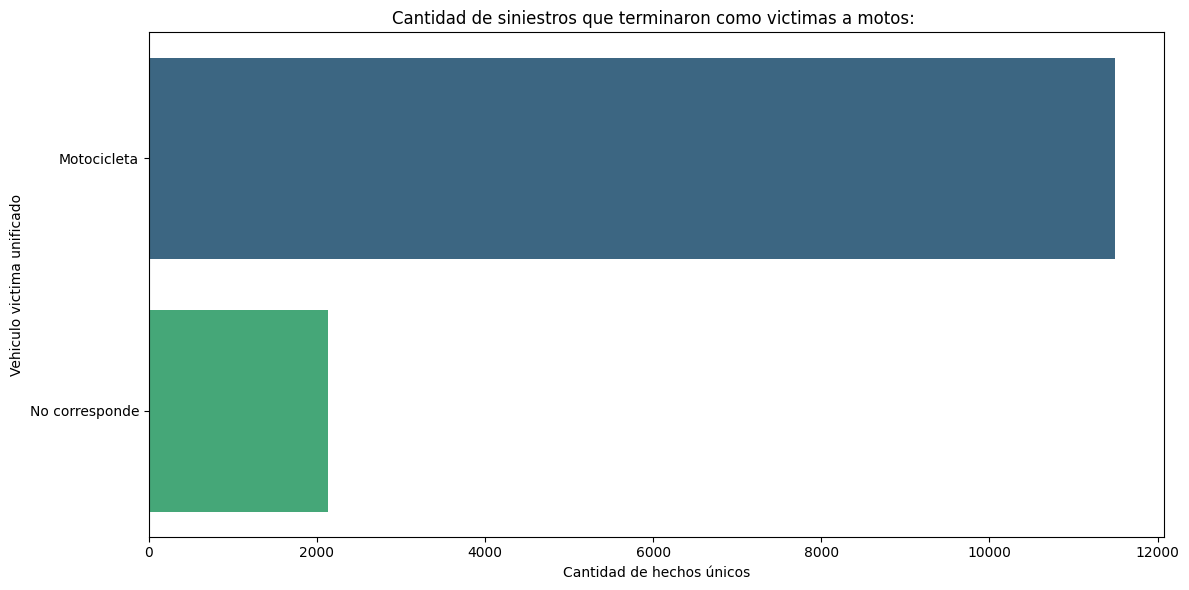

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Elige la columna que quieres analizar (puedes cambiarla por "tipo_lugar", "provincia_nombre", etc.)
columna_analisis = "vehiculo_victima_unificado"

# Calculamos frecuencia y porcentaje
frecuencia_datos = (
    df_modelo[columna_analisis]
    .value_counts()
    .rename_axis(columna_analisis)
    .reset_index(name="cantidad_hechos")
)

# Cfórmula del porcentaje
frecuencia_datos["porcentaje"] = (
    (frecuencia_datos["cantidad_hechos"] / frecuencia_datos["cantidad_hechos"].sum()) * 100
).round(2)

# Mostramos la tabla resultante
display(frecuencia_datos)

# 2. Gráfico de barras horizontales
plt.figure(figsize=(12, 6))
sns.barplot(
    data=frecuencia_datos,
    x="cantidad_hechos",
    y=columna_analisis,
    palette="viridis"  # Opcional: para darle nomas color
)
plt.title(f"Cantidad de siniestros que terminaron como victimas a motos: ")
plt.xlabel("Cantidad de hechos únicos")
plt.ylabel(columna_analisis.replace('_', ' ').capitalize())
plt.tight_layout()
plt.show()

Exploracion de la variable objetivo:
En cuantos de los siniestros los inculpados terminaron siendo motos

,vehiculo_inculpado_unificado,cantidad_hechos,porcentaje
0,No corresponde,11499,84.34
1,Motocicleta,2135,15.66


/tmp/ipykernel_7307/2897222681.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


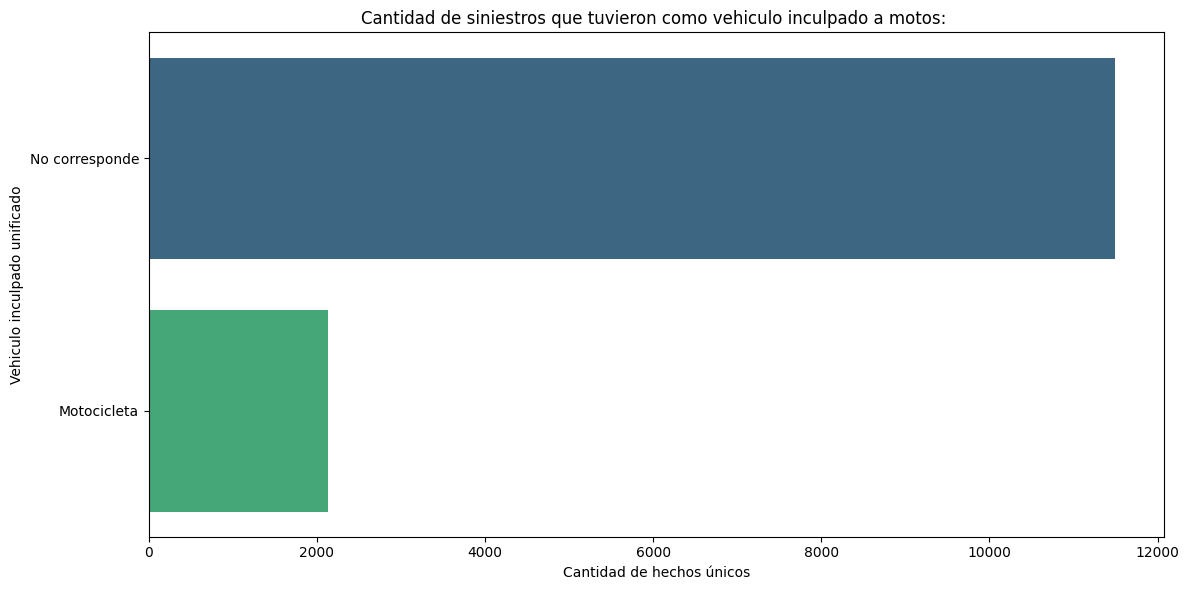

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. escribir la columna que se quiere analizar (puedes cambiarla por "tipo_lugar", "provincia_nombre", etc.)
columna_analisis = "vehiculo_inculpado_unificado"

# Calculamos frecuencia y porcentaje
frecuencia_datos = (
    df_modelo[columna_analisis]
    .value_counts()
    .rename_axis(columna_analisis)
    .reset_index(name="cantidad_hechos")
)

frecuencia_datos["porcentaje"] = (
    (frecuencia_datos["cantidad_hechos"] / frecuencia_datos["cantidad_hechos"].sum()) * 100
).round(2)

# Mostramos la tabla resultante
display(frecuencia_datos)

# 2. Gráfico de barras horizontales
plt.figure(figsize=(12, 6))
sns.barplot(
    data=frecuencia_datos,
    x="cantidad_hechos",
    y=columna_analisis,
    palette="viridis"
)
plt.title(f"Cantidad de siniestros que tuvieron como vehiculo inculpado a motos: ")
plt.xlabel("Cantidad de hechos únicos")
plt.ylabel(columna_analisis.replace('_', ' ').capitalize())
plt.tight_layout()
plt.show()

Cantidad de siniestros de motos ocurridos por Temporada

Cantidad y porcentaje de siniestros por temporada:


,temporada,cantidad_hechos,porcentaje
0,Verano,3687,27.04
1,Primavera,3493,25.62
2,Otoño,3243,23.79
3,Invierno,3211,23.55


/tmp/ipykernel_7307/3405780797.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


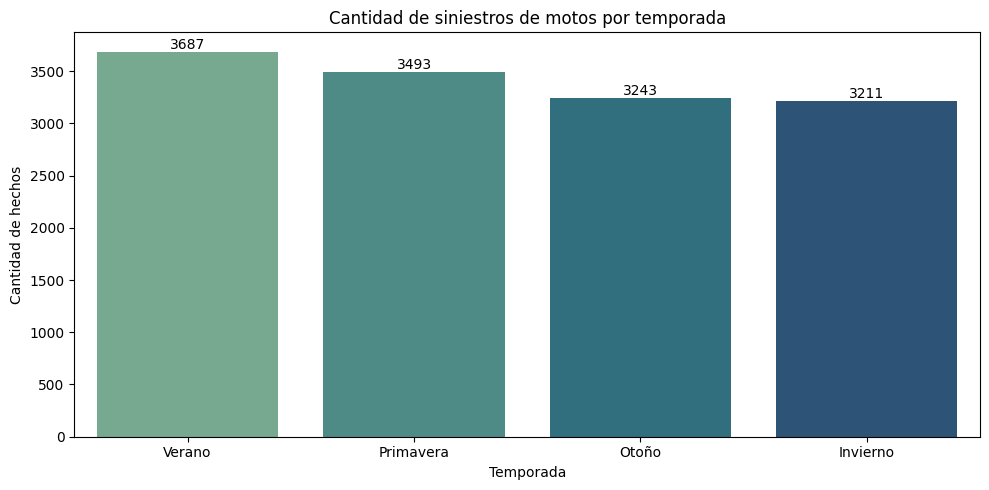

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupamos y contamos la cantidad de siniestros por temporada
frecuencia_temporada = (
    df_modelo["temporada"]
    .value_counts()
    .reset_index(name="cantidad_hechos")
)

# Calculamos también el porcentaje
frecuencia_temporada["porcentaje"] = (
    (frecuencia_temporada["cantidad_hechos"] / frecuencia_temporada["cantidad_hechos"].sum()) * 100
).round(2)

# Ordenamos de mayor a menor
frecuencia_temporada = frecuencia_temporada.sort_values(by="cantidad_hechos", ascending=False)

# Mostramos la tabla con los valores impresos
print("Cantidad y porcentaje de siniestros por temporada:")
display(frecuencia_temporada)

# 2. Creamos el gráfico de barras
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=frecuencia_temporada,
    x="temporada",
    y="cantidad_hechos",
    palette="crest"
)

# Agregamos el número exacto arriba de cada barra
for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center',
        xytext=(0, 5),
        textcoords='offset points'
    )

plt.title("Cantidad de siniestros de motos por temporada")
plt.xlabel("Temporada")
plt.ylabel("Cantidad de hechos")
plt.tight_layout()
plt.show()

Por Provincia

Cantidad y porcentaje de siniestros por provincia:


,provincia_nombre,cantidad_hechos,porcentaje
23,"Tierra del Fuego, Antártida e Islas del Atlánt...",13,0.10
22,Santa Cruz,19,0.14
21,Chubut,37,0.27
20,La Pampa,73,0.54
19,Neuquén,118,0.87
18,Río Negro,145,1.06
17,Jujuy,245,1.80
16,San Luis,276,2.02
15,La Rioja,287,2.11
14,Catamarca,331,2.43


/tmp/ipykernel_7307/3308952446.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


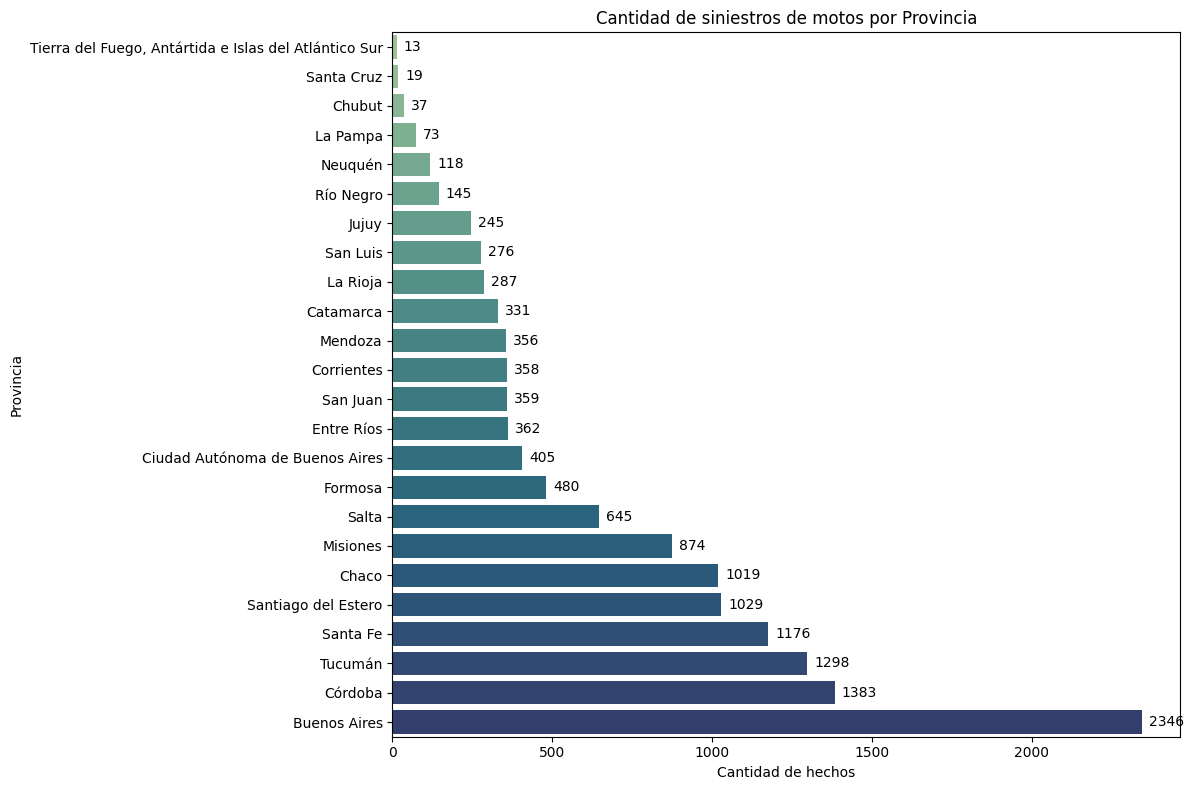

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupamos y contamos la cantidad de siniestros por provincia
frecuencia_provincia_nombre = (
    df_modelo["provincia_nombre"]
    .value_counts()
    .reset_index(name="cantidad_hechos")
)

# Calculamos también el porcentaje
frecuencia_provincia_nombre["porcentaje"] = (
    (frecuencia_provincia_nombre["cantidad_hechos"] / frecuencia_provincia_nombre["cantidad_hechos"].sum()) * 100
).round(2)

# Ordenamos de mayor a menor para que la provincia con más siniestros quede arriba
frecuencia_provincia_nombre = frecuencia_provincia_nombre.sort_values(by="cantidad_hechos", ascending=True)

# Mostramos la tabla con los valores impresos
print("Cantidad y porcentaje de siniestros por provincia:")
display(frecuencia_provincia_nombre)

# 2. Creamos el gráfico de barras HORIZONTALES
plt.figure(figsize=(12, 8))
ax = sns.barplot(
    data=frecuencia_provincia_nombre,
    x="cantidad_hechos",
    y="provincia_nombre",  # Pasamos provincia al eje Y, esto mas que nada porque si lo ponemos como eje X se sobreponen los nombres de provincia
   #como son 23 en total queda feo visualmente
    palette="crest"
)


for p in ax.patches:
    width = p.get_width()
    ax.annotate(
        f"{int(width)}",
        (width, p.get_y() + p.get_height() / 2.),
        ha='left', va='center',
        xytext=(5, 0),
        textcoords='offset points'
    )

plt.title("Cantidad de siniestros de motos por Provincia")
plt.xlabel("Cantidad de hechos")
plt.ylabel("Provincia")
plt.tight_layout()
plt.show()

Por Franja horaria

Cantidad y porcentaje de siniestros por franja horaria:


,franja_horaria,cantidad_hechos,porcentaje
0,Noche,4601,33.75
1,Mañana,3299,24.20
2,Madrugada,3013,22.10
3,Tarde,2721,19.96


/tmp/ipykernel_7307/1391847693.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


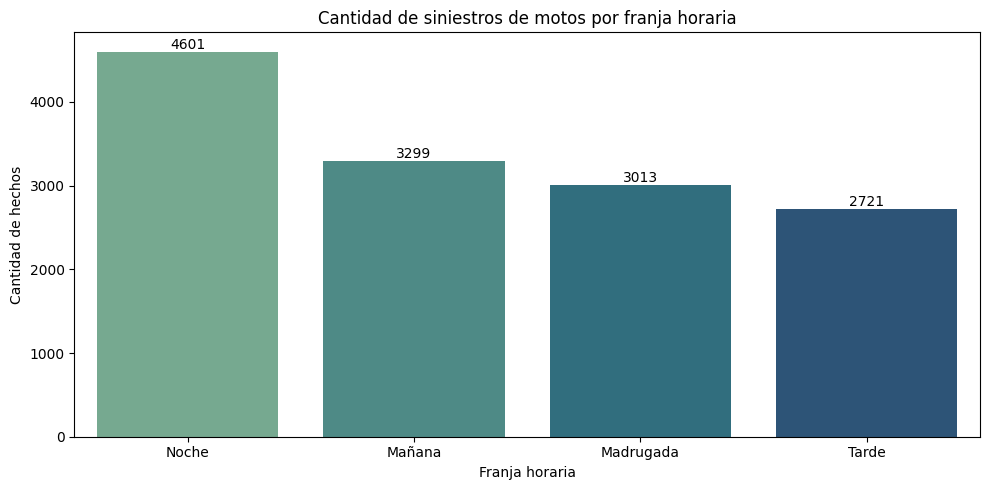

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupamos y contamos la cantidad de siniestros por franja horaria
frecuencia_franja_horaria = (
    df_modelo["franja_horaria"]
    .value_counts()
    .reset_index(name="cantidad_hechos")
)

# Calculamos también el porcentaje
frecuencia_franja_horaria["porcentaje"] = (
    (frecuencia_franja_horaria["cantidad_hechos"] / frecuencia_franja_horaria["cantidad_hechos"].sum()) * 100
).round(2)

# Ordenamos de mayor a menor
frecuencia_franja_horaria = frecuencia_franja_horaria.sort_values(by="cantidad_hechos", ascending=False)

# Mostramos la tabla con los valores impresos
print("Cantidad y porcentaje de siniestros por franja horaria:")
display(frecuencia_franja_horaria)

# 2. Creamos el gráfico de barras
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=frecuencia_franja_horaria,
    x="franja_horaria",
    y="cantidad_hechos",
    palette="crest"
)

# Agregamos el número exacto arriba de cada barra (corregido)
for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center',
        xytext=(0, 5),
        textcoords='offset points'
    )

plt.title("Cantidad de siniestros de motos por franja horaria")
plt.xlabel("Franja horaria")
plt.ylabel("Cantidad de hechos")
plt.tight_layout()
plt.show()

Por Tipo lugar

Cantidad y porcentaje de siniestros por franja horaria:


,tipo_lugar,cantidad_hechos,porcentaje
0,Calle,7533,55.25
1,Ruta,5112,37.49
2,Autopista / Autovía,609,4.47
3,Otro / Genérico,380,2.79


/tmp/ipykernel_7307/2417345499.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


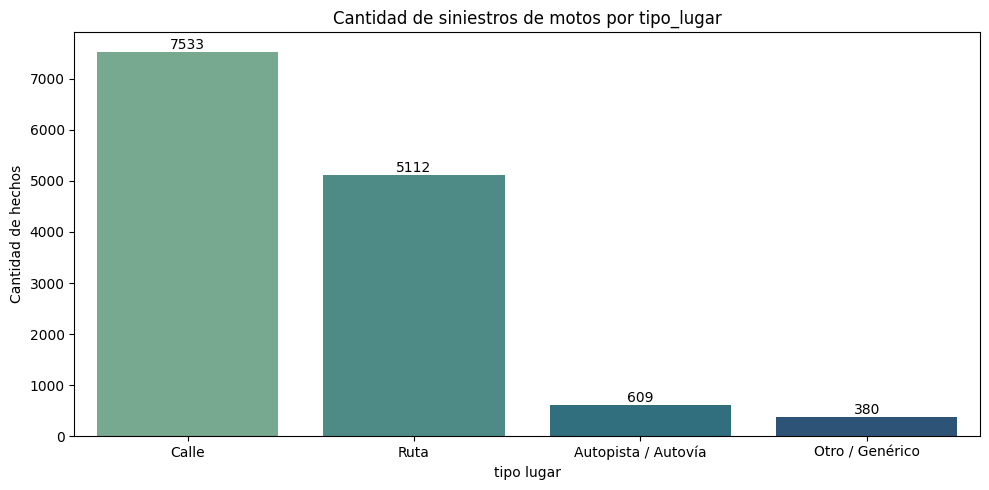

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupamos y contamos la cantidad de siniestros por franja horaria
frecuencia_tipo_lugar = (
    df_modelo["tipo_lugar"]
    .value_counts()
    .reset_index(name="cantidad_hechos")
)

# Calculamos también el porcentaje
frecuencia_tipo_lugar["porcentaje"] = (
    (frecuencia_tipo_lugar["cantidad_hechos"] / frecuencia_franja_horaria["cantidad_hechos"].sum()) * 100
).round(2)

# Ordenamos de mayor a menor
frecuencia_franja_horaria = frecuencia_franja_horaria.sort_values(by="cantidad_hechos", ascending=False)

# Mostramos la tabla con los valores impresos
print("Cantidad y porcentaje de siniestros por franja horaria:")
display(frecuencia_tipo_lugar)

# 2. Creamos el gráfico de barras
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=frecuencia_tipo_lugar,
    x="tipo_lugar",
    y="cantidad_hechos",
    palette="crest"
)

# Agregamos el número exacto arriba de cada barra (corregido)
for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center',
        xytext=(0, 5),
        textcoords='offset points'
    )

plt.title("Cantidad de siniestros de motos por tipo_lugar")
plt.xlabel("tipo lugar")
plt.ylabel("Cantidad de hechos")
plt.tight_layout()
plt.show()

CORRELACION DE LA CANTIDAD DE SINIESTROS QUE INVOLUCREN MOTOS CON LAS VARIABLES PREDICTORAS SELECCIONADAS

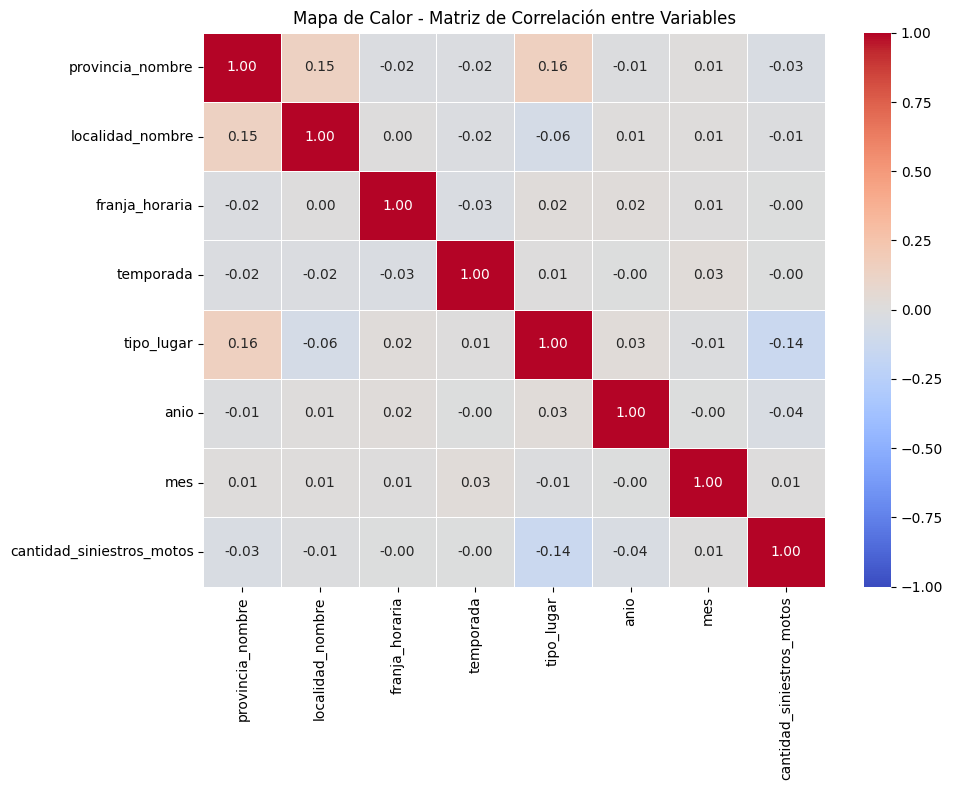

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# 1. Creamos una copia del dataset agregado para no alterar el original
df_heatmap = df_agregado.copy()

# 2. Convertimos todas las columnas categóricas a códigos numéricos enteros
# (Ejemplo: Buenos Aires = 0, CABA = 1, Córdoba = 2, etc.)
le = LabelEncoder()
for col in df_heatmap.select_dtypes(include=['object', 'category']).columns:
    df_heatmap[col] = le.fit_transform(df_heatmap[col].astype(str))

# 3. Calculamos la matriz de correlación completa
matriz_corr = df_heatmap.corr()

# 4. Creamos el Mapa de Calor
plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    cbar=True
)

plt.title("Mapa de Calor - Matriz de Correlación entre Variables")
plt.tight_layout()
plt.show()

In [26]:
#omitir esto
df_analisis = df_modelo.merge(
    df_agregado,
    on=variables_existentes,
    how="left"
).copy()

# ==========================================
#  FILTROS REUTILIZABLES
# ==========================================
def filtrar_siniestros_motos(datos, provincia=None, anio=None, temporada=None):
    resultado = datos.copy()
    if provincia is not None:
        resultado = resultado[resultado["provincia_nombre"] == provincia]
    if anio is not None:
        resultado = resultado[resultado["anio"] == anio]
    if temporada is not None:
        resultado = resultado[resultado["temporada"] == temporada]
    return resultado

df_filtrado = filtrar_siniestros_motos(df_analisis, provincia="Buenos Aires", anio=2023, temporada="Verano")
print("Registros filtrados de prueba:", len(df_filtrado))


Registros filtrados de prueba: 71


Sección 6: Machine Learning (Modelos de Regresión Cuantitativa)

Registros de entrenamiento (2017-2023): 3898
Registros de prueba (Año 2024): 562

Evaluación del año 2024 — Regresión Lineal
• MAE: 1.5178
• RMSE: 2.1286
• R2 Score: 0.3193


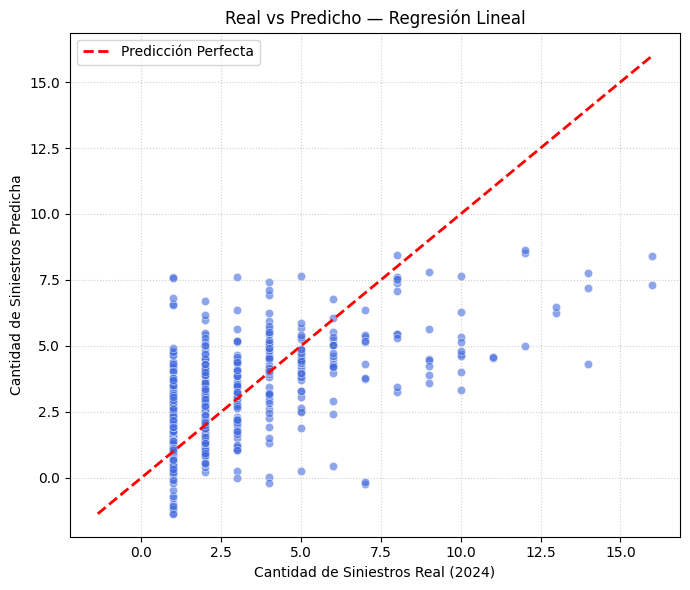


Evaluación del año 2024 — Regresión de Poisson
• MAE: 1.7671
• RMSE: 2.4038
• R2 Score: 0.1319


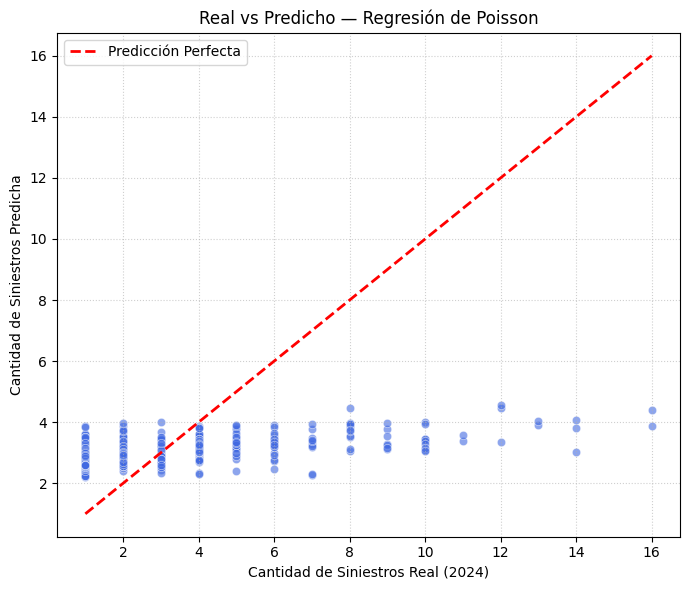


Evaluación del año 2024 — Random Forest Regressor
• MAE: 1.2970
• RMSE: 1.9427
• R2 Score: 0.4330


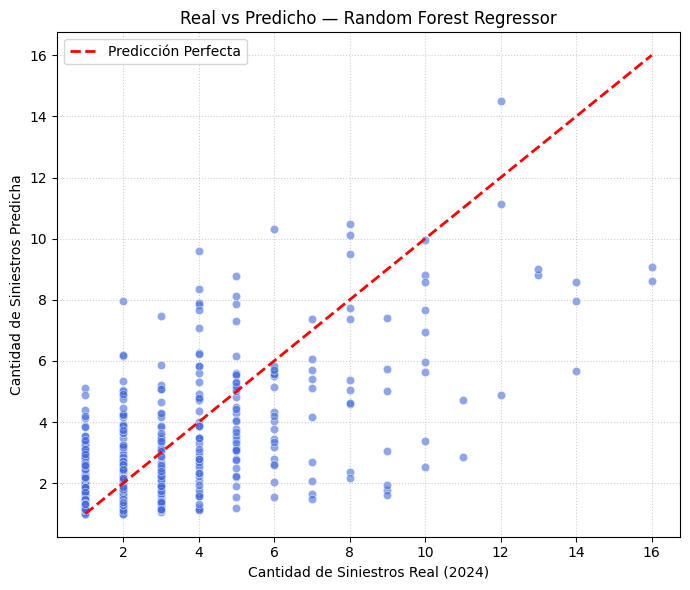


COMPARACIÓN GENERAL DE MODELOS (PREDICCIÓN 2024)


,Modelo,MAE,RMSE,R2 Score
0,Random Forest Regressor,1.2970,1.9427,0.4330
1,Regresión Lineal,1.5178,2.1286,0.3193
2,Regresión de Poisson,1.7671,2.4038,0.1319


In [27]:

# DATOS USADO PARA ENTRENAMIENTO: 2017-2023, DATOS USADOS PARA TESTEO: 2024)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import time
variables_predictoras = [
    "franja_horaria",
    "tipo_lugar",
    "temporada",
    "anio",
    "provincia_nombre"
]

variable_objetivo = "cantidad_siniestros_motos"

# Agregamos "anio" para poder filtrar por el año 2024
df_ml = df_agregado.groupby(variables_predictoras, as_index=False)[variable_objetivo].sum().dropna().copy()

# Separación temporal
df_train = df_ml[df_ml["anio"] < 2024]
df_test = df_ml[df_ml["anio"] == 2024]

X_train = df_train[variables_predictoras]
y_train = df_train[variable_objetivo]

X_test = df_test[variables_predictoras]
y_test = df_test[variable_objetivo]

print(f"Registros de entrenamiento (2017-2023): {len(X_train)}")
print(f"Registros de prueba (Año 2024): {len(X_test)}")

preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_predictoras
        )
    ],
    remainder="drop"
)

modelos_regresion = {
    "Regresión Lineal": LinearRegression(),
    "Regresión de Poisson": PoissonRegressor(max_iter=1000),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    )
}

resultados = []
modelos_entrenados = {}
predicciones = {}

for nombre, modelo in modelos_regresion.items():
    pipeline = Pipeline([
        ("preprocesador", preprocesador),
        ("modelo", modelo)
    ])

    inicio = time.time()
    # Entrenamos con datos históricos (< 2024)
    pipeline.fit(X_train, y_train)

    # Predecimos sobre el año 2024
    y_pred = pipeline.predict(X_test)


    modelos_entrenados[nombre] = pipeline
    predicciones[nombre] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)


    resultados.append({
        "Modelo": nombre,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2 Score": round(r2, 4),

    })

    print(f"\n{'=' * 55}")
    print(f"Evaluación del año 2024 — {nombre}")
    print(f"{'=' * 55}")
    print(f"• MAE: {mae:.4f}")
    print(f"• RMSE: {rmse:.4f}")
    print(f"• R2 Score: {r2:.4f}")


    # GRÁFICO DE VALORES REALES VS PREDICHOS (CADA MODELO)

    plt.figure(figsize=(7, 6))

    # Gráfico de dispersión
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color="royalblue")


    min_val = min(min(y_test), min(y_pred))
    max_val = max(max(y_test), max(y_pred))
    plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", lw=2, label="Predicción Perfecta")

    plt.title(f"Real vs Predicho — {nombre}")
    plt.xlabel("Cantidad de Siniestros Real (2024)")
    plt.ylabel("Cantidad de Siniestros Predicha")
    plt.legend()
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()
comparacion = pd.DataFrame(resultados).sort_values(
    "R2 Score", ascending=False
).reset_index(drop=True)

print("\nCOMPARACIÓN GENERAL DE MODELOS (PREDICCIÓN 2024)")
display(comparacion)


El modelo de Random Forest Regressor obtuvo el mejor desempeño global gracias a un $R^2$ Score más alto (0.4330) y un RMSE menor (1.9427), además de presentar el MAE más bajo (1.2970). Esto demuestra una precisión superior y una mayor estabilidad frente a los errores grandes en comparación con los otros algoritmos en este conjunto de datos, explicando de forma más efectiva la varianza general de los datos.

* MAE(Error Absoluto Medio / Mean Absolute Error): Mide en promedio la magnitud de los errores de las predicciones, expresado en la misma unidad que la variable objetivo (cantidad de siniestros). Indica por cuántas unidades se desvía en promedio el modelo respecto a la realidad.

* RMSE(Raíz del Error Cuadrático Medio / Root Mean Squared Error): Calcula la raíz cuadrada de la media de los errores al cuadrado. Penaliza con mayor fuerza los errores grandes o atípicos, siendo muy útil para detectar si el modelo comete desviaciones severas en determinadas provincias o franjas horarias.

* $R^2$ Score(Coeficiente de Determinación): Representa la proporción de la varianza total de la cantidad de siniestros que es explicada por el modelo a partir de las variables predictoras. Un valor cercano a 1 indica un ajuste óptimo, mientras que valores bajos reflejan los desafíos de predecir la variabilidad futura.



Sección 7: Reentrenamiento Final y Predicción con el 100% de los Datos (2017-2024)


*En la sección anterior evaluamos nuestros modelos separando un año de prueba (2024) para saber qué tan bien predecían. Ahora que ya sabemos cuál modelo funcionó mejor, el objetivo de negocio cambia: queremos generar la mejor predicción posible hacia adelante. Por lo tanto, volvemos a entrenar el modelo utilizando todos nuestros datos históricos disponibles (desde 2017 hasta 2024 inclusive). Así, el algoritmo aprovecha la máxima cantidad de información posible.*

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

# 1. Definimos las variables predictoras y la variable objetivo
variables_predictoras = [
    "franja_horaria",
    "tipo_lugar",
    "temporada",
    "anio",
    "provincia_nombre"
]
variable_objetivo = "cantidad_siniestros_motos"


df_final_ml = df_agregado[variables_predictoras + [variable_objetivo]].dropna().copy()

X_full = df_final_ml[variables_predictoras]
y_full = df_final_ml[variable_objetivo]


preprocesador = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), variables_predictoras)
    ]
)

#Seleccionamos el mejor modelo según nuestra evaluación previa (Random Forest)
modelo_ganador = RandomForestRegressor()

pipeline_final = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("modelo", modelo_ganador)
])


pipeline_final.fit(X_full, y_full)



Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['franja_horaria',
                                                   'tipo_lugar', 'temporada',
                                                   'anio',
                                                   'provincia_nombre'])])),
                ('modelo', RandomForestRegressor())])

In [29]:
import pandas as pd

# Creamos un caso hipotético para consultar al modelo:
# ¿Cuántos siniestros se estiman en la Provincia de Buenos Aires, durante la Noche, en Verano y en una Ruta?
nuevo_caso = pd.DataFrame({
    "franja_horaria": ["Noche"],
    "tipo_lugar": ["Ruta"],
    "temporada": ["Verano"],
    "anio": [2024],
    "provincia_nombre": ["Buenos Aires"]
})

# Predicción final
prediccion_siniestros = pipeline_final.predict(nuevo_caso)

print(f"Cantidad estimada de siniestros de motos para el escenario planteado: {prediccion_siniestros[0]:.2f}")

Cantidad estimada de siniestros de motos para el escenario planteado: 1.00


In [30]:

# COMPARATIVA DE ESCENARIOS (2017-2023 vs  2017-2024)


from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np

# Definir características y variable objetivo
features = ["provincia_nombre", "franja_horaria", "temporada", "tipo_lugar"]
target = "cantidad_siniestros_motos"

#  MODELO 1: EntrenaMOS solo con 2017-2023
df_train_orig = df_agregado[df_agregado["anio"].between(2017, 2023)].copy()
df_test_2024 = df_agregado[df_agregado["anio"] == 2024].copy()

X_train_orig = pd.get_dummies(df_train_orig[features], drop_first=True)
y_train_orig = df_train_orig[target]

X_test_2024 = pd.get_dummies(df_test_2024[features], drop_first=True)
X_test_2024 = X_test_2024.reindex(columns=X_train_orig.columns, fill_value=0)

modelo_orig = RandomForestRegressor(n_estimators=100, random_state=42)
modelo_orig.fit(X_train_orig, y_train_orig)

# Predicción del modelo original sobre el 2024
pred_orig_2023 = modelo_orig.predict(X_test_2024)


# 2. MODELO 2: Reentrenamos con el total de los datos (2017-2024)
df_train_full = df_agregado[df_agregado["anio"].between(2017, 2024)].copy()

X_train_full = pd.get_dummies(df_train_full[features], drop_first=True)
y_train_full = df_train_full[target]


X_test_2024_full = pd.get_dummies(df_test_2024[features], drop_first=True)
X_test_2024_full = X_test_2024_full.reindex(columns=X_train_full.columns, fill_value=0)

modelo_full = RandomForestRegressor(n_estimators=100, random_state=42)
modelo_full.fit(X_train_full, y_train_full)

# Predicción del modelo reentrenado sobre el 2024
pred_reentrenado_full = modelo_full.predict(X_test_2024_full)


# 3. CONSTRUCCIÓN DE LA TABLA COMPARATIVA FINAL
df_tabla_comparativa = df_test_2024[features].copy()
df_tabla_comparativa["Pred_Original_2023"] = np.round(pred_orig_2023, 2)
df_tabla_comparativa["Pred_Reentrenado_Full"] = np.round(pred_reentrenado_full, 2)
df_tabla_comparativa["Real_2024"] = df_test_2024[target].values

print("--- TABLA COMPARATIVA DE ESCENARIOS (2024) ---")
display(df_tabla_comparativa.head(15))

--- TABLA COMPARATIVA DE ESCENARIOS (2024) ---


,provincia_nombre,franja_horaria,temporada,tipo_lugar,Pred_Original_2023,Pred_Reentrenado_Full,Real_2024
17,Buenos Aires,Tarde,Otoño,Calle,1.08,1.07,1
32,Buenos Aires,Madrugada,Invierno,Calle,1.01,1.01,1
33,Buenos Aires,Madrugada,Otoño,Calle,1.12,1.11,1
38,Buenos Aires,Madrugada,Primavera,Otro / Genérico,1.00,1.06,1
45,Buenos Aires,Mañana,Otoño,Calle,1.06,1.05,1
50,Buenos Aires,Mañana,Verano,Calle,1.06,1.07,1
55,Buenos Aires,Noche,Invierno,Otro / Genérico,1.08,1.14,1
60,Buenos Aires,Noche,Otoño,Calle,1.08,1.07,1
61,Buenos Aires,Noche,Otoño,Calle,1.08,1.07,1
88,Buenos Aires,Noche,Primavera,Calle,1.09,1.11,1


**Escenario Real (Real_2024):** Corresponde a los datos oficiales de lo que efectivamente sucedió en cada localidad y combinación de variables durante el 2024.

**Predicción Modelo Original (Pred_Original_2023):** Muestra lo que el modelo predijo habiendo aprendido únicamente del pasado (2017–2023), simulando un testeo estricto sin conocer el 2024 de antemano.

**Predicción Modelo Reentrenado (Pred_Reentrenado_Full):** Muestra la estimación del modelo al que se le permitió incorporar toda la tendencia histórica (incluyendo el 2024), optimizado para responder consultas de negocio actuales.

*SECCION 8: ANALISIS DE MODELOS CON OTRAS VARIABLES

Luego de observar los resultados optamos por probar con otras variables predictoras para ver si mejoraban las predicciones

Las variables seleccionadas son:



##**Variables predictoras (x):**


* **Mes (`mes`)** — Mes en el que se registra el hecho.
* **Año (`anio`)** — Año en el que se registra el hecho.
* **Provincia (provincia_nombre)** - Provincia donde se registra el hecho


In [31]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Agrupamos los datos por año, mes y provincia para obtener la suma de siniestros
df_modelo = df_agregado.groupby(['anio', 'mes', 'provincia_nombre'], as_index=False)['cantidad_siniestros_motos'].sum()

print("Primeras filas de los datos preparados para los modelos:")
print(df_modelo.head())

Primeras filas de los datos preparados para los modelos:
   anio  mes                 provincia_nombre  cantidad_siniestros_motos
0  2017    1                     Buenos Aires                         25
1  2017    1                        Catamarca                          3
2  2017    1                            Chaco                          9
3  2017    1  Ciudad Autónoma de Buenos Aires                          6
4  2017    1                          Córdoba                         12


In [32]:
# Separar Variables Predictoras (X) y Objetivo (y), y división Train/Test
from sklearn.model_selection import train_test_split

# Definir predictoras (X) y objetivo (y)
X = df_modelo[['anio', 'mes', 'provincia_nombre']]
y = df_modelo['cantidad_siniestros_motos']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [33]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

#  transformamos la variable categórica 'provincia_nombre' a columnas binarias
preprocesador = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['provincia_nombre'])
    ],
    remainder='passthrough' # Mantiene 'anio' y 'mes' tal cual
)

pipeline_lr = Pipeline(steps=[('preproc', preprocesador), ('modelo', LinearRegression())])
pipeline_dt = Pipeline(steps=[('preproc', preprocesador), ('modelo', DecisionTreeRegressor(random_state=42))])
pipeline_rf = Pipeline(steps=[('preproc', preprocesador), ('modelo', RandomForestRegressor(random_state=42))])

pipeline_lr.fit(X_train, y_train)
pipeline_dt.fit(X_train, y_train)
pipeline_rf.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preproc',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['provincia_nombre'])])),
                ('modelo', RandomForestRegressor(random_state=42))])

In [34]:
# evaluamos y comparamos metricas
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Función para evaluar métricas
def evaluar_modelo(nombre, modelo, X_test, y_test):
    y_pred = modelo.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    return {'Modelo': nombre, 'MAE': mae, 'RMSE': rmse, 'R2': r2}

# Evaluamos los tres modelos
resultados = [
    evaluar_modelo('Regresión Lineal', pipeline_lr, X_test, y_test),
    evaluar_modelo('Árbol de Decisión', pipeline_dt, X_test, y_test),
    evaluar_modelo('Random Forest', pipeline_rf, X_test, y_test)
]

# DataFrame resumen con los resultados
df_resultados = pd.DataFrame(resultados)
print("\n--- TABLA COMPARATIVA DE MÉTRICAS ---")
print(df_resultados.to_string(index=False))


--- TABLA COMPARATIVA DE MÉTRICAS ---
           Modelo      MAE     RMSE       R2
 Regresión Lineal 2.359568 3.658253 0.720104
Árbol de Decisión 2.760417 4.088857 0.650334
    Random Forest 2.244141 3.242288 0.780137


**Gráficos para Comparar los Modelos**

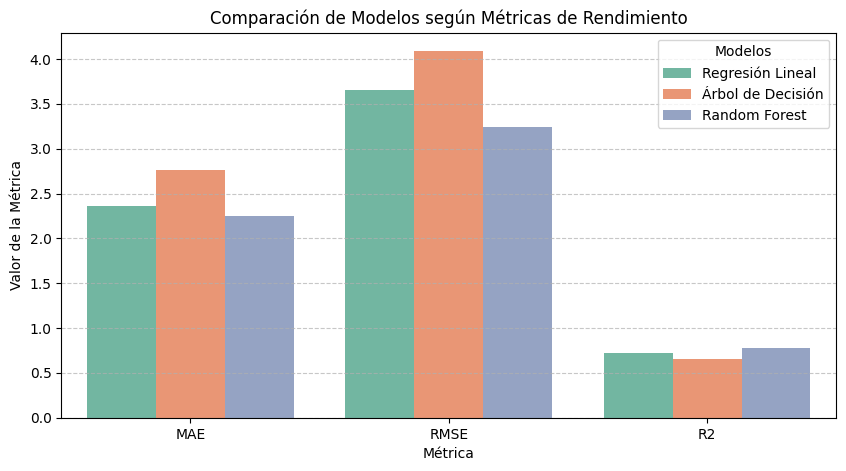

In [35]:
# Grafico de barras comparativo de métricas

df_melted = df_resultados.melt(id_vars='Modelo', value_vars=['MAE', 'RMSE', 'R2'],
                               var_name='Metrica', value_name='Valor')

plt.figure(figsize=(10, 5))
sns.barplot(data=df_melted, x='Metrica', y='Valor', hue='Modelo', palette='Set2')
plt.title('Comparación de Modelos según Métricas de Rendimiento')
plt.ylabel('Valor de la Métrica')
plt.xlabel('Métrica')
plt.legend(title='Modelos')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

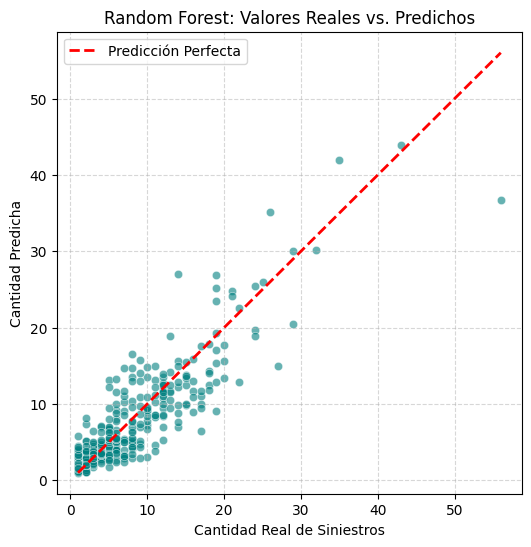

In [36]:
# Gráfico de dispersión: Real vs. Predicho (Random Forest)
y_pred_rf = pipeline_rf.predict(X_test)

plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_test, y=y_pred_rf, alpha=0.6, color='teal')

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Predicción Perfecta')
plt.title('Random Forest: Valores Reales vs. Predichos')
plt.xlabel('Cantidad Real de Siniestros')
plt.ylabel('Cantidad Predicha')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()